<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/euler_cromer_exact.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simple Pendulum solution comparison: Euler, Cromer and Exact.


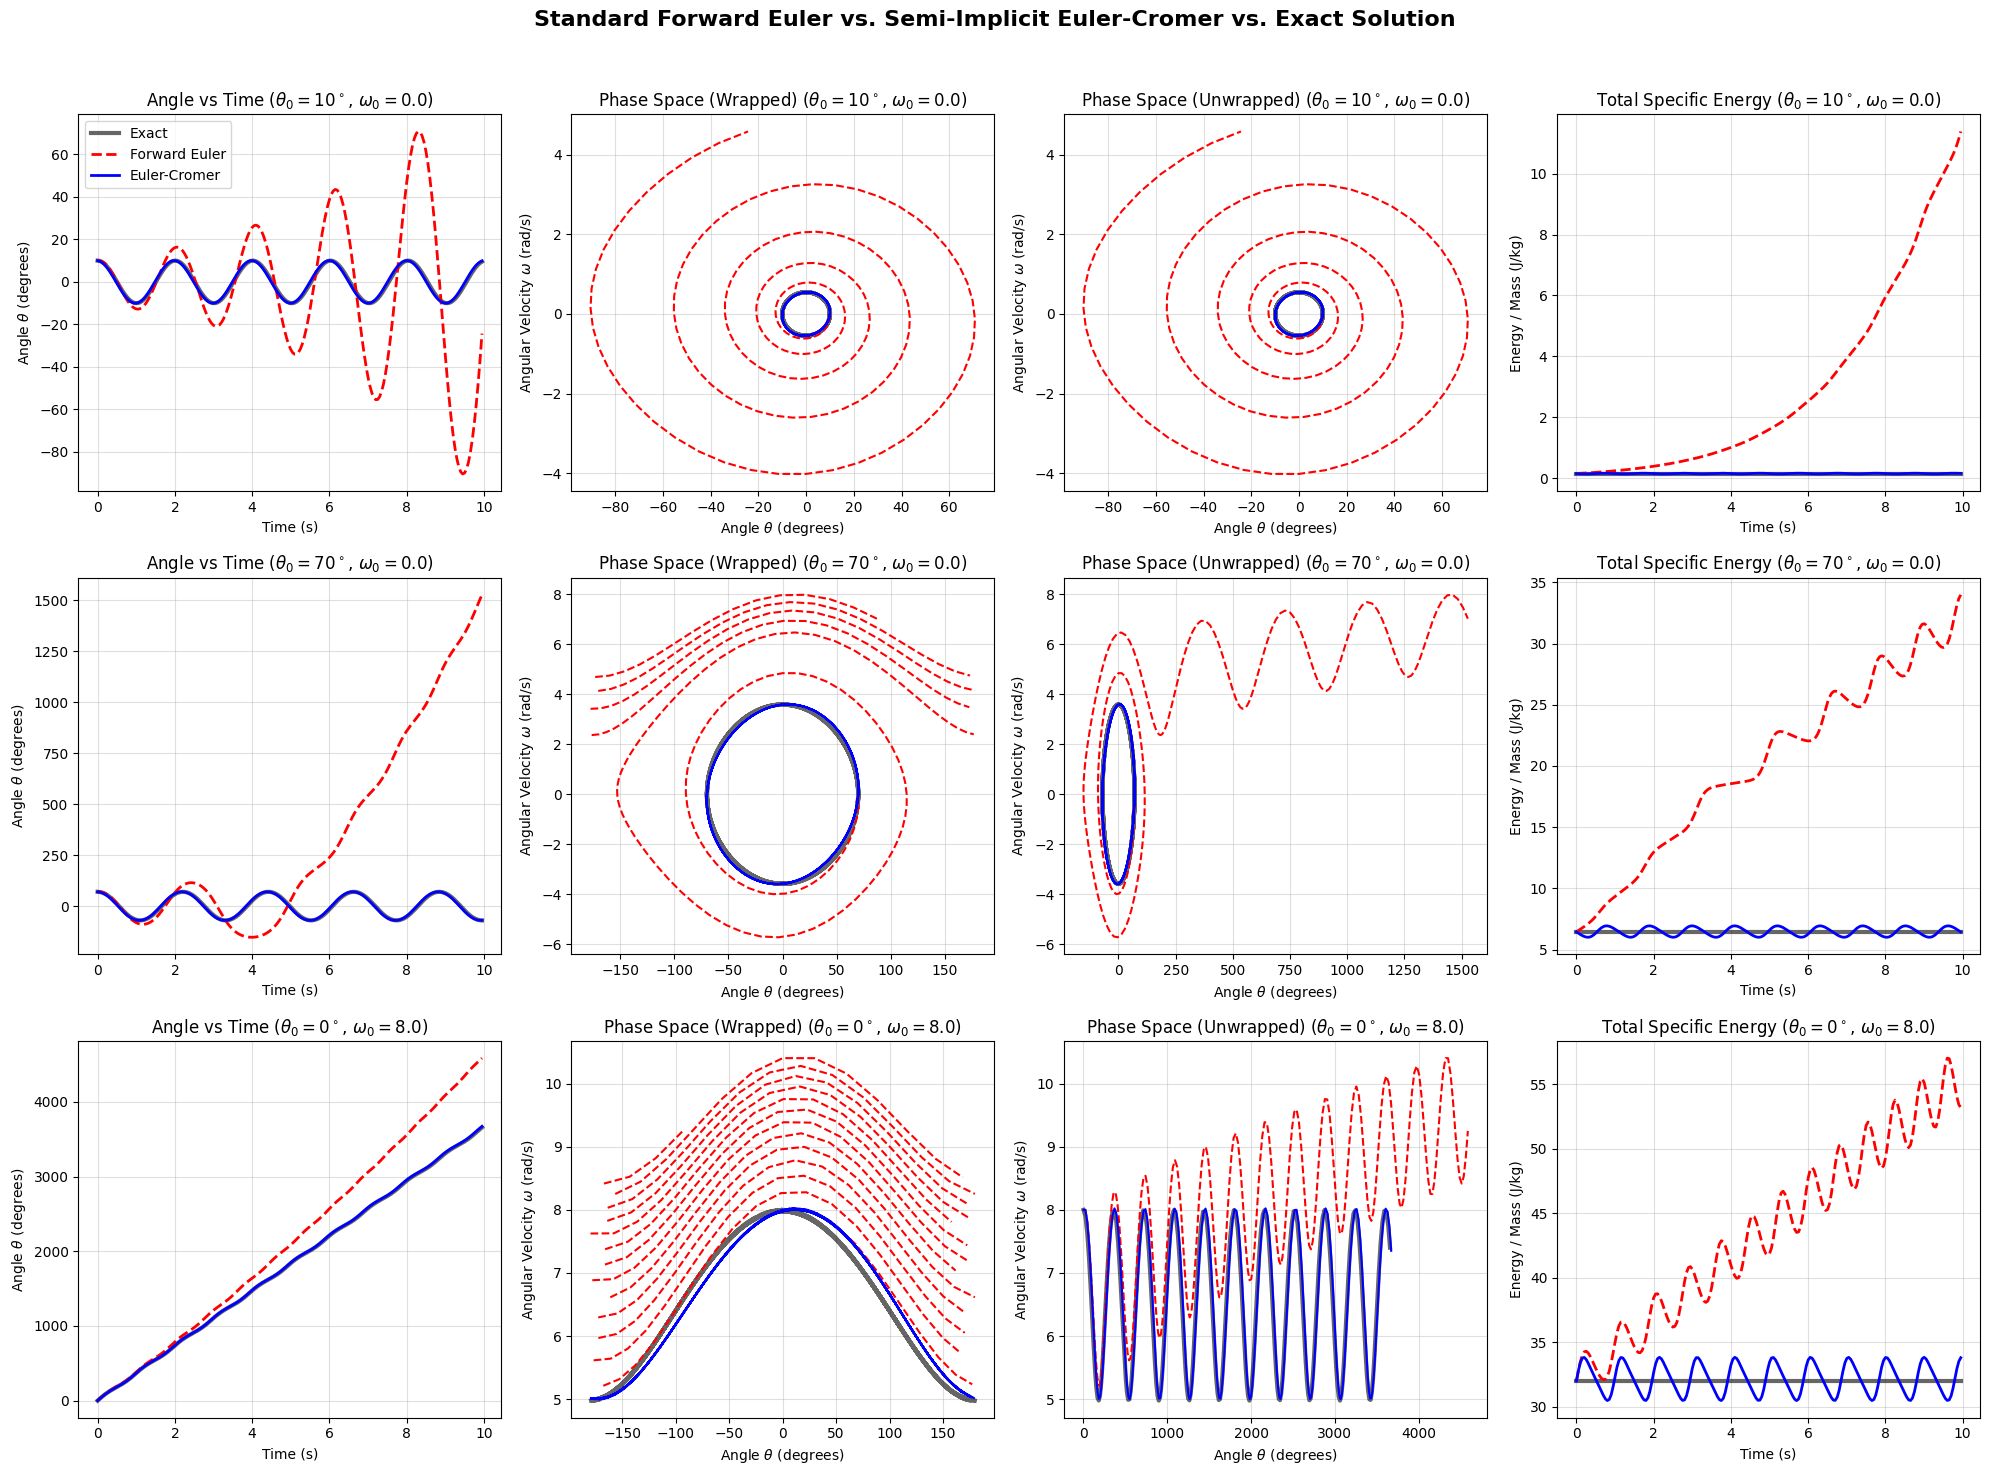

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==========================================
# 1. Physical Parameters & Simulation Function
# ==========================================
g = 9.81        # Acceleration due to gravity (m/s^2)
l = 1.0         # Length of the pendulum (m)

def calc_energy(theta, omega):
    """Calculates specific energy (E/m) = 1/2*(l*w)^2 + gl(1-cos(theta))"""
    return 0.5 * (l * omega)**2 + g * l * (1 - np.cos(theta))

def simulate_pendulum(theta_0_deg, omega_0=0.0, dt=0.05, t_max=10.0):
    """Runs Forward Euler, Euler-Cromer, and Exact simulations for given initial conditions."""
    t = np.arange(0, t_max, dt)
    n_steps = len(t)

    theta_0 = np.radians(theta_0_deg)

    # Arrays for numerical methods
    theta_euler = np.zeros(n_steps)
    omega_euler = np.zeros(n_steps)
    energy_euler = np.zeros(n_steps)

    theta_cromer = np.zeros(n_steps)
    omega_cromer = np.zeros(n_steps)
    energy_cromer = np.zeros(n_steps)

    # Set initial conditions
    theta_euler[0] = theta_0
    omega_euler[0] = omega_0
    theta_cromer[0] = theta_0
    omega_cromer[0] = omega_0

    energy_euler[0] = calc_energy(theta_euler[0], omega_euler[0])
    energy_cromer[0] = calc_energy(theta_cromer[0], omega_cromer[0])

    # ----------------------------------------------------
    # Exact Solution (using highly accurate numerical integration)
    # ----------------------------------------------------
    def exact_deriv(t, y):
        return [y[1], -(g / l) * np.sin(y[0])]

    sol = solve_ivp(exact_deriv, [0, t_max], [theta_0, omega_0], t_eval=t, rtol=1e-11, atol=1e-11)
    theta_exact = sol.y[0]
    omega_exact = sol.y[1]
    energy_exact = calc_energy(theta_exact, omega_exact)

    # ----------------------------------------------------
    # Integration Loops for Euler and Euler-Cromer
    # ----------------------------------------------------
    for i in range(n_steps - 1):
        # Standard Forward Euler (Both calculated using OLD values)
        theta_euler[i+1] = theta_euler[i] + omega_euler[i] * dt
        omega_euler[i+1] = omega_euler[i] - (g / l) * np.sin(theta_euler[i]) * dt
        energy_euler[i+1] = calc_energy(theta_euler[i+1], omega_euler[i+1])

        # Semi-Implicit Euler-Cromer (Calculate NEW omega first, use for NEW theta)
        omega_cromer[i+1] = omega_cromer[i] - (g / l) * np.sin(theta_cromer[i]) * dt
        theta_cromer[i+1] = theta_cromer[i] + omega_cromer[i+1] * dt
        energy_cromer[i+1] = calc_energy(theta_cromer[i+1], omega_cromer[i+1])

    return t, (np.degrees(theta_euler), omega_euler, energy_euler), \
              (np.degrees(theta_cromer), omega_cromer, energy_cromer), \
              (np.degrees(theta_exact), omega_exact, energy_exact)

# ==========================================
# 2. Run Simulations
# ==========================================
dt = 0.05
t_max = 10.0

# 1. Small angle swinging
res_small = simulate_pendulum(theta_0_deg=10, omega_0=0.0, dt=dt, t_max=t_max)
# 2. Large angle swinging
res_large = simulate_pendulum(theta_0_deg=70, omega_0=0.0, dt=dt, t_max=t_max)
# 3. Continuous Rotation (Start at bottom with large initial velocity)
res_rot = simulate_pendulum(theta_0_deg=0.0, omega_0=8.0, dt=dt, t_max=t_max)

# ==========================================
# 3. Plotting the Comparison
# ==========================================
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle('Standard Forward Euler vs. Semi-Implicit Euler-Cromer vs. Exact Solution', fontsize=16, weight='bold', y=0.98)

def wrap_phase(theta, omega):
    """Wraps the angle to [-180, 180] and inserts NaNs to prevent drawing lines across the plot."""
    theta_wrapped = (theta + 180) % 360 - 180
    jumps = np.abs(np.diff(theta_wrapped)) > 180
    jump_idx = np.where(jumps)[0] + 1
    theta_plot = np.insert(theta_wrapped, jump_idx, np.nan)
    omega_plot = np.insert(omega, jump_idx, np.nan)
    return theta_plot, omega_plot

def plot_row(ax_row, t, euler, cromer, exact, th0, om0):
    """Helper function to plot a single row of 4 charts."""
    ax1, ax2, ax3, ax4 = ax_row
    te, oe, ee = euler
    tc, oc, ec = cromer
    tx, ox, ex = exact

    title_params = f'$\\theta_0 = {th0}^\\circ$, $\\omega_0 = {om0}$'

    # --- Plot 1: Angle vs Time ---
    ax1.plot(t, tx, 'k-', linewidth=3, alpha=0.6, label='Exact')
    ax1.plot(t, te, 'r--', linewidth=2, label='Forward Euler')
    ax1.plot(t, tc, 'b-', linewidth=2, label='Euler-Cromer')
    ax1.set_title(f'Angle vs Time ({title_params})', fontsize=12)
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Angle $\\theta$ (degrees)')
    ax1.grid(True, alpha=0.4)
    if ax_row[0] == axes[0, 0]: # Only put legend on the first plot to save space
        ax1.legend()

    # --- Plot 2: Phase Space (Wrapped) ---
    # Wrap the phase angles to [-180, 180] for standard phase space representation
    tx_w, ox_w = wrap_phase(tx, ox)
    te_w, oe_w = wrap_phase(te, oe)
    tc_w, oc_w = wrap_phase(tc, oc)

    ax2.plot(tx_w, ox_w, 'k-', linewidth=3, alpha=0.6, label='Exact')
    ax2.plot(te_w, oe_w, 'r--', linewidth=1.5, label='Forward Euler')
    ax2.plot(tc_w, oc_w, 'b-', linewidth=1.5, label='Euler-Cromer')
    ax2.set_title(f'Phase Space (Wrapped) ({title_params})', fontsize=12)
    ax2.set_xlabel('Angle $\\theta$ (degrees)')
    ax2.set_ylabel('Angular Velocity $\\omega$ (rad/s)')
    ax2.grid(True, alpha=0.4)

    # --- Plot 3: Phase Space (Unwrapped) ---
    ax3.plot(tx, ox, 'k-', linewidth=3, alpha=0.6, label='Exact')
    ax3.plot(te, oe, 'r--', linewidth=1.5, label='Forward Euler')
    ax3.plot(tc, oc, 'b-', linewidth=1.5, label='Euler-Cromer')
    ax3.set_title(f'Phase Space (Unwrapped) ({title_params})', fontsize=12)
    ax3.set_xlabel('Angle $\\theta$ (degrees)')
    ax3.set_ylabel('Angular Velocity $\\omega$ (rad/s)')
    ax3.grid(True, alpha=0.4)

    # --- Plot 4: Total Energy over Time ---
    ax4.plot(t, ex, 'k-', linewidth=3, alpha=0.6, label='Exact')
    ax4.plot(t, ee, 'r--', linewidth=2, label='Forward Euler')
    ax4.plot(t, ec, 'b-', linewidth=2, label='Euler-Cromer')
    ax4.set_title(f'Total Specific Energy ({title_params})', fontsize=12)
    ax4.set_xlabel('Time (s)')
    ax4.set_ylabel('Energy / Mass (J/kg)')
    ax4.grid(True, alpha=0.4)

# Plot small angle, large angle, and rotational results row by row
plot_row(axes[0], res_small[0], res_small[1], res_small[2], res_small[3], 10, 0.0)
plot_row(axes[1], res_large[0], res_large[1], res_large[2], res_large[3], 70, 0.0)
plot_row(axes[2], res_rot[0], res_rot[1], res_rot[2], res_rot[3], 0, 8.0)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()